# Examen Parcial II – Minería de Datos II
##  Limpieza y estadística – Online Retail


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from limpieza_datos import LimpiezaOnlineRetail

## 1. Cargar los datos

In [2]:
limpieza = LimpiezaOnlineRetail('Online Retail.xlsx')
datos = limpieza.cargar()
datos.shape

(541909, 8)

In [3]:
datos.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
# Nulos antes de limpiar
datos.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

## 2. Limpieza
La clase hace la limpieza paso a paso y guarda cuántas filas quita en cada uno.

In [5]:
datos = limpieza.limpiar()
datos.shape

(391147, 12)

In [6]:
limpieza.resumen()

,paso,filas_eliminadas
0,Duplicados,5268
1,Cancelaciones (factura con C),9251
2,Códigos que no son producto,2406
3,Cantidad o precio <= 0,2480
4,Líneas de más de £10.000,3
5,Description nula,0
6,CustomerID nulo,131354


In [7]:
# Nulos después de limpiar 
datos.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
Mes            0
Dia            0
Hora           0
dtype: int64

In [8]:
datos.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,Mes,Dia,Hora
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,Miércoles,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Miércoles,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,Miércoles,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Miércoles,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Miércoles,8


## 3. Estadísticas básicas

In [9]:
datos.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID,TotalPrice,Hora
count,391147.000000,391147,391147.000000,391147.0,391147.000000,391147.000000
mean,12.748440,2011-07-10 19:37:46.254273,2.872726,15295.176558,21.609790,12.723002
min,1.000000,2010-12-01 08:26:00,0.040000,12347.0,0.060000,6.000000
25%,2.000000,2011-04-07 11:16:00,1.250000,13969.0,4.950000,11.000000
50%,6.000000,2011-07-31 12:05:00,1.950000,15159.0,11.900000,13.000000
75%,12.000000,2011-10-20 12:57:00,3.750000,16794.0,19.800000,14.000000
max,4800.000000,2011-12-09 12:50:00,649.500000,18287.0,7144.720000,20.000000
std,42.999039,NaN,4.158141,1710.338072,70.975736,2.275991


In [10]:
numericas = datos[['Quantity', 'UnitPrice', 'TotalPrice']]
numericas.mean()

Quantity      12.748440
UnitPrice      2.872726
TotalPrice    21.609790
dtype: float64

In [11]:
numericas.median()

Quantity       6.00
UnitPrice      1.95
TotalPrice    11.90
dtype: float64

In [12]:
numericas.std(ddof = 1)

Quantity      42.999039
UnitPrice      4.158141
TotalPrice    70.975736
dtype: float64

In [13]:
numericas.quantile(np.array([0, .25, .50, .75, .95, 1]))

,Quantity,UnitPrice,TotalPrice
0.00,1.0,0.04,0.06
0.25,2.0,1.25,4.95
0.50,6.0,1.95,11.90
0.75,12.0,3.75,19.80
0.95,40.0,8.50,67.50
1.00,4800.0,649.50,7144.72


In [14]:
print('Moda de Quantity:', datos['Quantity'].mode()[0])
print('Asimetría (skew):')
numericas.skew()

Moda de Quantity: 1
Asimetría (skew):


Quantity      29.948166
UnitPrice     29.436013
TotalPrice    29.826970
dtype: float64

In [15]:
# Correlación entre las variables numéricas
numericas.corr()

,Quantity,UnitPrice,TotalPrice
Quantity,1.000000,-0.083967,0.665655
UnitPrice,-0.083967,1.000000,0.092564
TotalPrice,0.665655,0.092564,1.000000


In [16]:
print('Facturas:', datos['InvoiceNo'].nunique())
print('Productos:', datos['Description'].nunique())
print('Clientes:', datos['CustomerID'].nunique())
print('Países:', datos['Country'].nunique())
print('Desde', datos['InvoiceDate'].min(), 'hasta', datos['InvoiceDate'].max())

Facturas: 18399
Productos: 3632
Clientes: 4333
Países: 37
Desde 2010-12-01 08:26:00 hasta 2011-12-09 12:50:00


In [17]:
# Clientes: cuánto concentran las compras
ventas_cliente = datos.groupby('CustomerID')['TotalPrice'].sum().sort_values(ascending=False)
n20 = int(len(ventas_cliente) * 0.2)
print('Top 5 clientes:')
print(ventas_cliente.head(5).round(0))
print('El 20% de los clientes genera', round(ventas_cliente.head(n20).sum() / ventas_cliente.sum() * 100, 1), '% de las ventas')

Top 5 clientes:
CustomerID
14646    279138.0
18102    259657.0
17450    194391.0
14911    136162.0
12415    124565.0
Name: TotalPrice, dtype: float64
El 20% de los clientes genera 73.8 % de las ventas


## 4. Gráficos

### Países con más ventas

In [18]:
# Ventas totales por país y su porcentaje
ventas_pais = datos.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False)
pd.DataFrame({'Ventas (£)': ventas_pais.round(0), '% del total': (ventas_pais / ventas_pais.sum() * 100).round(1)}).head(10)

,Ventas (£),% del total
Country,,
United Kingdom,6958232.0,82.3
Netherlands,283889.0,3.4
EIRE,257013.0,3.0
Germany,205381.0,2.4
France,183802.0,2.2
Australia,138104.0,1.6
Spain,55707.0,0.7
Switzerland,52442.0,0.6
Japan,37416.0,0.4


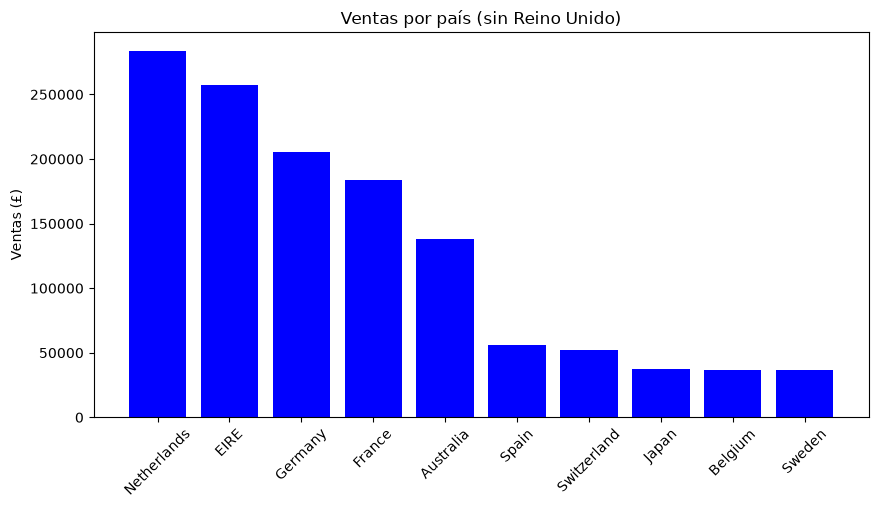

In [19]:
# Reino Unido es casi todo, por eso se grafica sin él
paises = datos[datos['Country'] != 'United Kingdom'].groupby('Country')['TotalPrice'].sum().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize = (10,5), dpi = 100)
ax.bar(paises.index, paises.values, color='blue')
ax.set_title('Ventas por país (sin Reino Unido)')
ax.set_ylabel('Ventas (£)')
plt.xticks(rotation=45)
plt.show()

### Ventas por mes

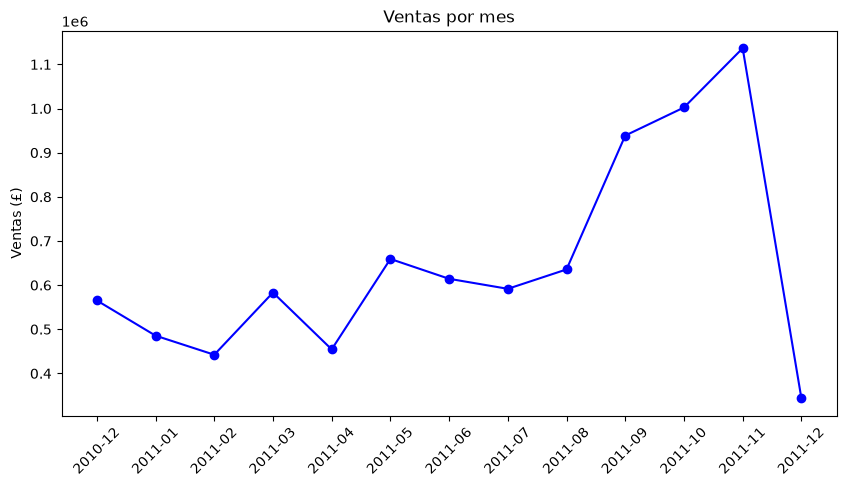

In [20]:
ventas_mes = datos.groupby('Mes')['TotalPrice'].sum()

fig, ax = plt.subplots(nrows=1, ncols=1, figsize = (10,5), dpi = 100)
ax.plot(ventas_mes.index, ventas_mes.values, marker='o', color='blue')
ax.set_title('Ventas por mes')
ax.set_ylabel('Ventas (£)')
plt.xticks(rotation=45)
plt.show()

diciembre de 2011 baja porque los datos terminan el 9 de diciembre (mes incompleto), no porque las ventas caigan.
El crecimiento fuerte empieza en septiembre y llega al máximo en noviembre (£1.14 millones).

### Facturas por día de la semana y por hora

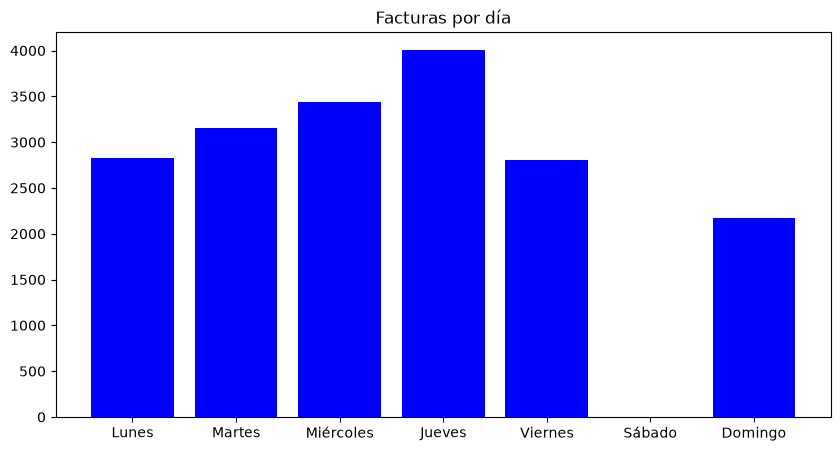

In [21]:
facturas_dia = datos.groupby('Dia')['InvoiceNo'].nunique().reindex(limpieza.DIAS).fillna(0)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize = (10,5), dpi = 100)
ax.bar(facturas_dia.index, facturas_dia.values, color='blue')
ax.set_title('Facturas por día')
plt.show()

 no hay facturas los sábados en todo el dataset y el jueves es el día más fuerte (4003 facturas).

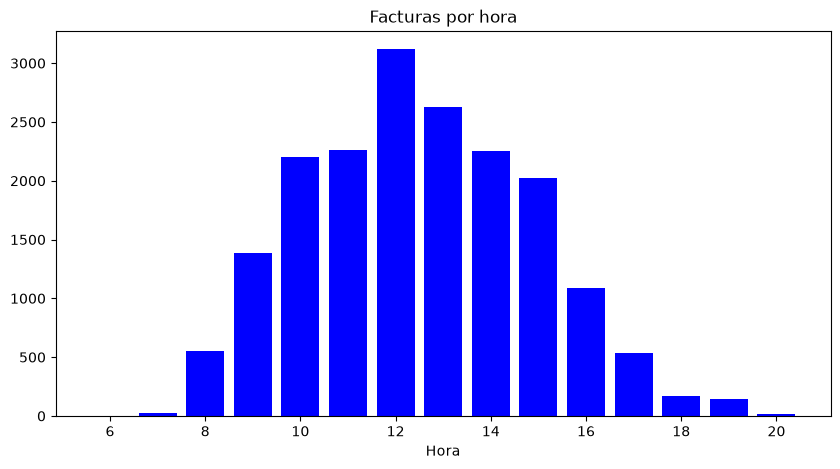

In [22]:
facturas_hora = datos.groupby('Hora')['InvoiceNo'].nunique()

fig, ax = plt.subplots(nrows=1, ncols=1, figsize = (10,5), dpi = 100)
ax.bar(facturas_hora.index, facturas_hora.values, color='blue')
ax.set_title('Facturas por hora')
ax.set_xlabel('Hora')
plt.show()

 casi todas las compras ocurren entre las 8 y las 17 horas, con el pico al mediodía (12:00, 3118 facturas).

### Productos más vendidos
Se cuenta en cuántas facturas aparece cada producto.

In [23]:
top_productos = datos.groupby('Description')['InvoiceNo'].nunique().sort_values(ascending=False).head(10)
top_productos

Description
WHITE HANGING HEART T-LIGHT HOLDER    1978
REGENCY CAKESTAND 3 TIER              1703
JUMBO BAG RED RETROSPOT               1600
PARTY BUNTING                         1379
ASSORTED COLOUR BIRD ORNAMENT         1375
LUNCH BAG RED RETROSPOT               1289
SET OF 3 CAKE TINS PANTRY DESIGN      1146
JUMBO BAG VINTAGE DOILY               1080
LUNCH BAG  BLACK SKULL.               1052
LUNCH BAG SUKI DESIGN                 1043
Name: InvoiceNo, dtype: int64

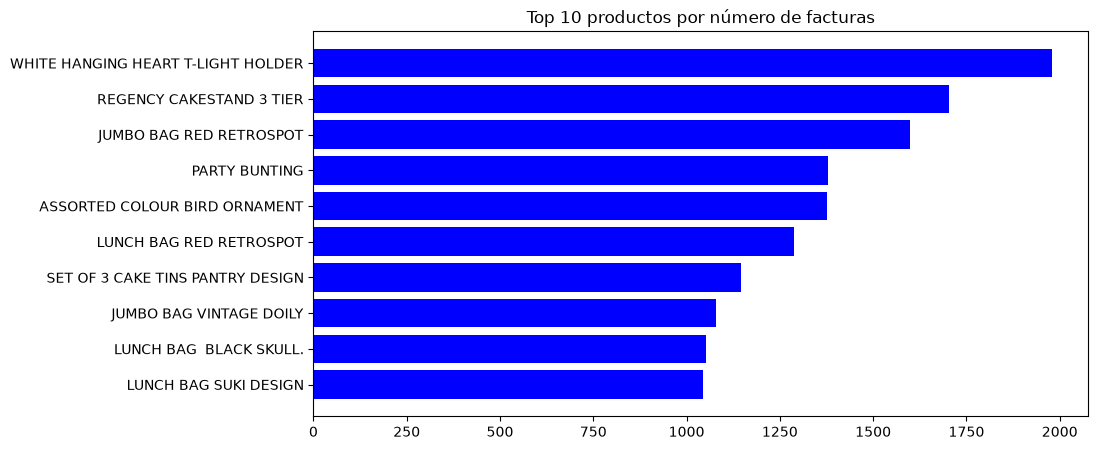

In [24]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize = (10,5), dpi = 100)
ax.barh(top_productos.index, top_productos.values, color='blue')
ax.invert_yaxis()
ax.set_title('Top 10 productos por número de facturas')
plt.show()

### Cantidad y precio

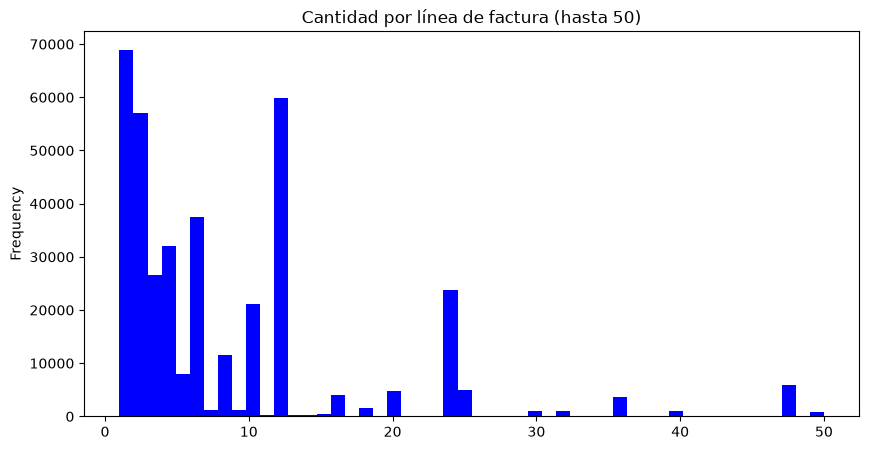

In [25]:
# Se recorta para que se pueda ver el grueso de los datos
fig, ax = plt.subplots(nrows=1, ncols=1, figsize = (10,5), dpi = 100)
datos[datos['Quantity'] <= 50]['Quantity'].plot(kind='hist', bins=50, ax=ax, color='blue')
ax.set_title('Cantidad por línea de factura (hasta 50)')
plt.show()

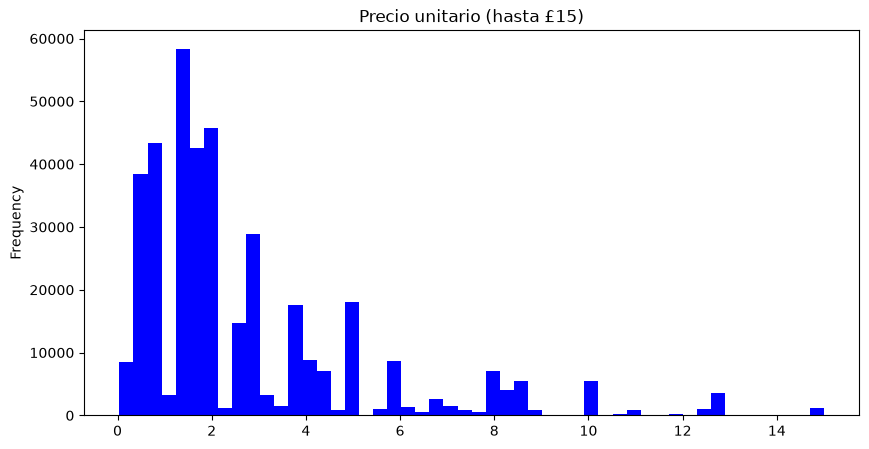

In [26]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize = (10,5), dpi = 100)
datos[datos['UnitPrice'] <= 15]['UnitPrice'].plot(kind='hist', bins=50, ax=ax, color='blue')
ax.set_title('Precio unitario (hasta £15)')
plt.show()

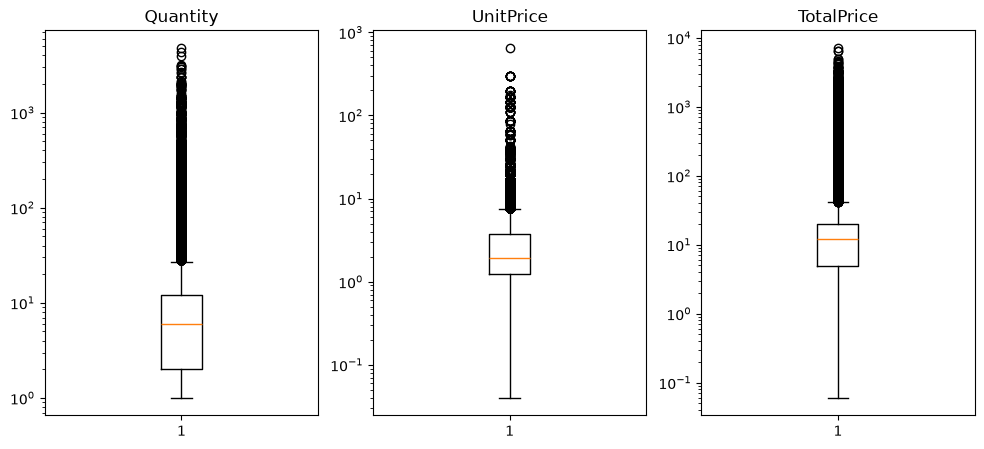

In [27]:
# Boxplot 
fig, ax = plt.subplots(nrows=1, ncols=3, figsize = (12,5), dpi = 100)
for i, col in enumerate(['Quantity', 'UnitPrice', 'TotalPrice']):
    ax[i].boxplot(datos[col])
    ax[i].set_yscale('log')
    ax[i].set_title(col)
plt.show()

In [28]:
productos_factura = datos.groupby('InvoiceNo')['StockCode'].nunique()
productos_factura.describe()

count    18399.000000
mean        20.996956
std         23.820094
min          1.000000
25%          7.000000
50%         15.000000
75%         27.000000
max        540.000000
Name: StockCode, dtype: float64

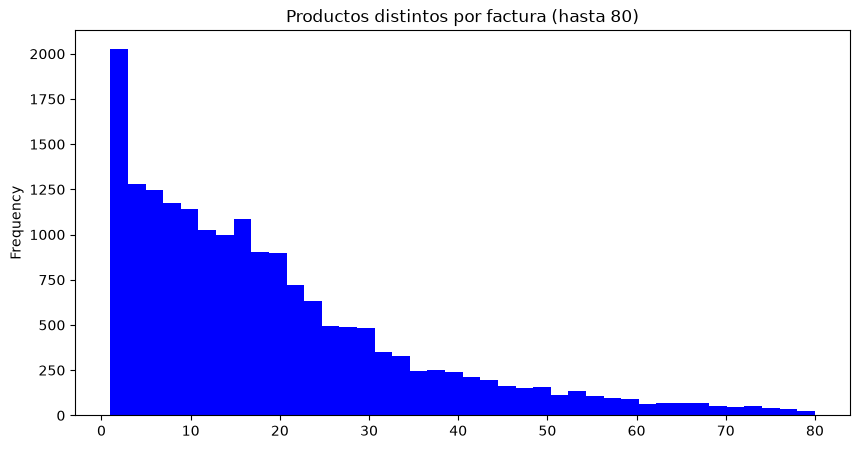

In [29]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize = (10,5), dpi = 100)
productos_factura[productos_factura <= 80].plot(kind='hist', bins=40, ax=ax, color='blue')
ax.set_title('Productos distintos por factura (hasta 80)')
plt.show()

La mediana es de 15 productos por factura

## 5. Matriz de canastas y archivo limpio

In [30]:
# Matriz facturas x producto
matriz = limpieza.matriz_canasta(pais='United Kingdom')
print(matriz.shape)

(15365, 3612)


In [31]:
limpieza.guardar('online_retail_limpio.csv')

## 6. Muestra de 2 000 filas para las reglas de asociación

El EDA de arriba se hizo con **todos** los datos limpios (391 147 filas), porque ahí se quiere ver el comportamiento real de la tienda.
Pero para correr Apriori, FP-Growth y Eclat el grupo usa una **muestra de 2 000 filas** (`2mil_online_retail.csv`) sacada de este mismo dataset ya limpio.
Aquí se genera esa muestra y se guarda desde el EDA, para que quede claro de dónde sale.

Cómo funciona (código en `muestra_datos.py`):
- La muestra son **90 facturas completas**, no filas sueltas. Si se eligieran filas al azar, las facturas quedarían partidas y se perderían los productos que se compran juntos, que es justo lo que buscan las reglas.
- El archivo tiene la lista de esas 90 facturas (`FACTURAS_MUESTRA`), las mismas que ya usa el grupo, y la función `crear_muestra()` filtra el dataset limpio con esa lista.

In [32]:
from muestra_datos import crear_muestra

muestra = crear_muestra(datos)
print('Filas:', len(muestra))
print('Facturas:', muestra['InvoiceNo'].nunique())
print('Productos distintos:', muestra['Description'].nunique())

Filas: 2000
Facturas: 90
Productos distintos: 1126


### ¿La muestra se parece al dataset completo?

Se comparan las medidas principales. No tienen que ser idénticas, pero sí parecidas; si no, la muestra no representaría bien a la tienda.

In [33]:
def resumen(d):
    por_factura = d.groupby('InvoiceNo')['StockCode'].nunique()
    return {
        'Filas': len(d),
        'Facturas': d['InvoiceNo'].nunique(),
        'Productos distintos': d['Description'].nunique(),
        'Mediana de Quantity': d['Quantity'].median(),
        'Mediana de UnitPrice': d['UnitPrice'].median(),
        'Mediana de TotalPrice': d['TotalPrice'].median(),
        'Mediana de productos por factura': por_factura.median(),
        '% de filas de Reino Unido': round((d['Country'] == 'United Kingdom').mean() * 100, 1),
    }

pd.DataFrame({'Completo': resumen(datos), 'Muestra (2 000)': resumen(muestra)})

,Completo,Muestra (2 000)
Filas,391147.00,2000.00
Facturas,18399.00,90.00
Productos distintos,3632.00,1126.00
Mediana de Quantity,6.00,6.00
Mediana de UnitPrice,1.95,1.95
Mediana de TotalPrice,11.90,12.60
Mediana de productos por factura,15.00,16.00
% de filas de Reino Unido,89.20,90.80


La mediana de cantidad y la de productos por factura son casi iguales (6 y 16 contra 6 y 15), el precio y el total son parecidos, y la muestra mantiene el predominio de Reino Unido (91 % contra 89 %).
Las diferencias grandes (facturas y productos distintos) son esperables: una muestra de 2 000 filas no puede tener los 3 632 productos del dataset completo.


### Gráficos con la muestra

Los mismos gráficos del EDA, ahora con los 2 000 datos, para ver cómo queda lo que van a usar las reglas.

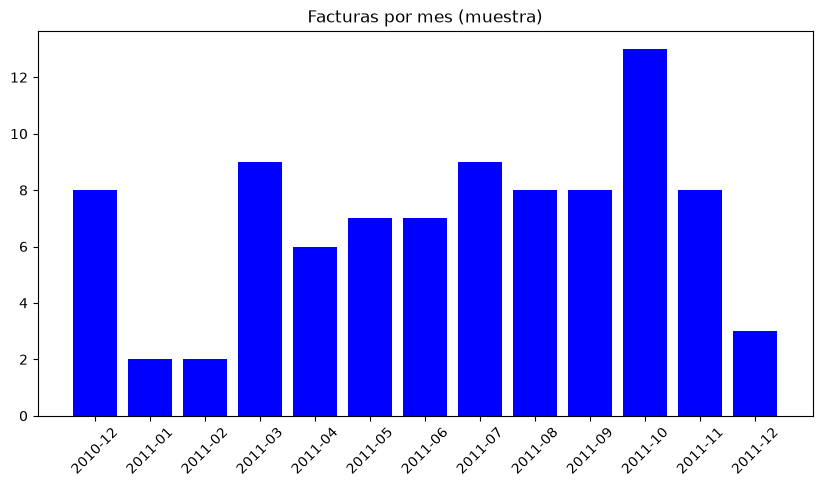

In [34]:
# Facturas por mes
facturas_mes = muestra.groupby('Mes')['InvoiceNo'].nunique()

fig, ax = plt.subplots(nrows=1, ncols=1, figsize = (10,5), dpi = 100)
ax.bar(facturas_mes.index, facturas_mes.values, color='blue')
ax.set_title('Facturas por mes (muestra)')
plt.xticks(rotation=45)
plt.show()

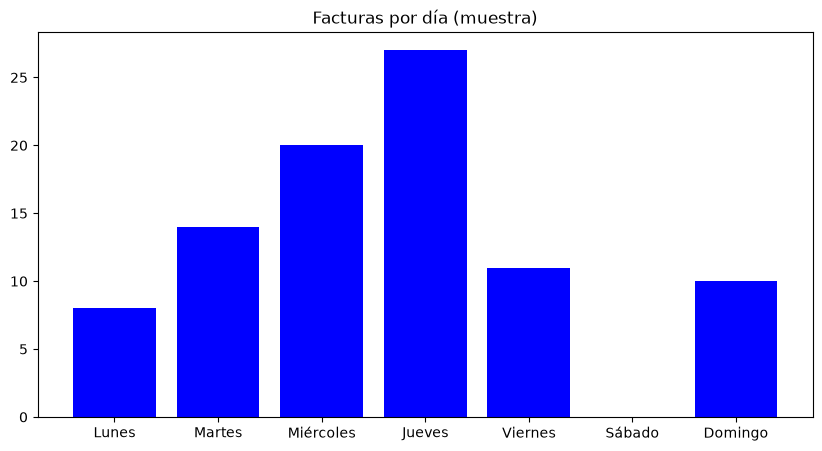

In [35]:
# Facturas por día de la semana
facturas_dia_m = muestra.groupby('Dia')['InvoiceNo'].nunique().reindex(limpieza.DIAS).fillna(0)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize = (10,5), dpi = 100)
ax.bar(facturas_dia_m.index, facturas_dia_m.values, color='blue')
ax.set_title('Facturas por día (muestra)')
plt.show()

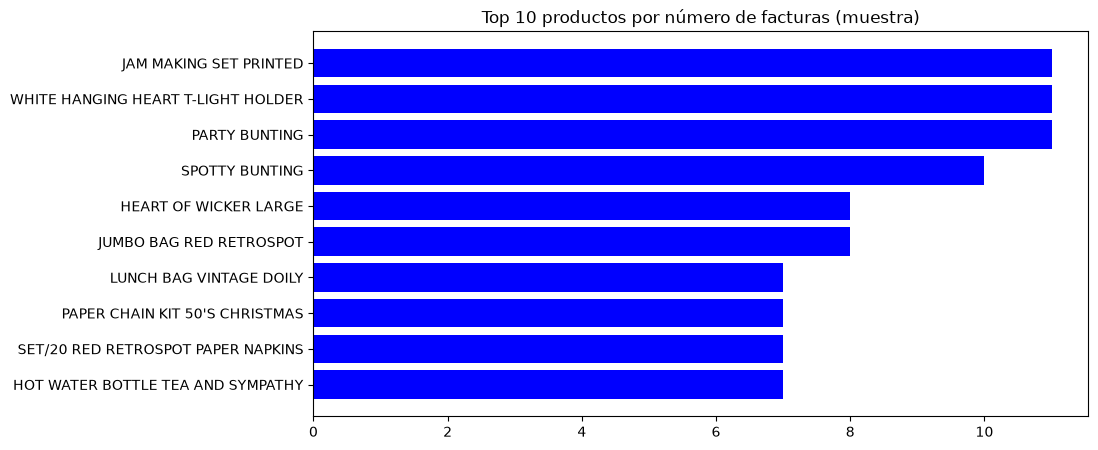

In [36]:
# Top 10 productos de la muestra
top_muestra = muestra.groupby('Description')['InvoiceNo'].nunique().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize = (10,5), dpi = 100)
ax.barh(top_muestra.index, top_muestra.values, color='blue')
ax.invert_yaxis()
ax.set_title('Top 10 productos por número de facturas (muestra)')
plt.show()

count     90.0
mean      21.9
std       21.4
min        1.0
25%        5.2
50%       16.0
75%       28.8
max      113.0


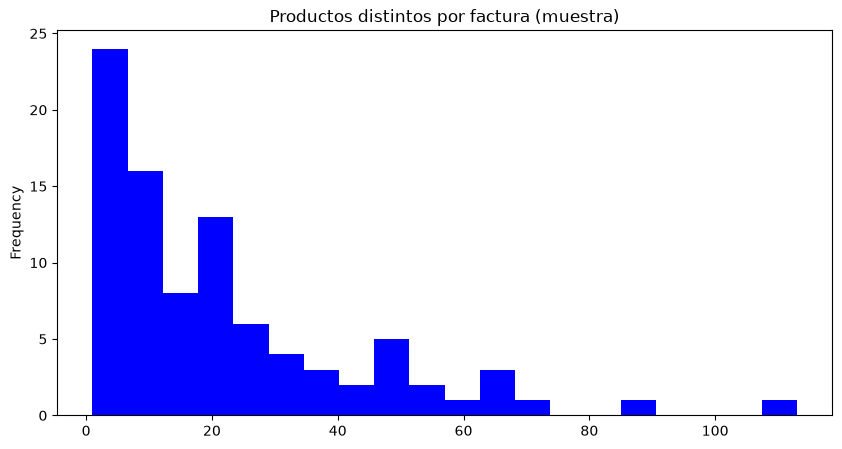

In [37]:
# Productos distintos por factura en la muestra
productos_factura_m = muestra.groupby('InvoiceNo')['StockCode'].nunique()
print(productos_factura_m.describe().round(1).to_string())

fig, ax = plt.subplots(nrows=1, ncols=1, figsize = (10,5), dpi = 100)
productos_factura_m.plot(kind='hist', bins=20, ax=ax, color='blue')
ax.set_title('Productos distintos por factura (muestra)')
plt.show()

**Qué dicen:** con solo 90 facturas, cada producto aparece en muy pocas (los más populares están en 11), por eso para las reglas hay que usar un 

### Guardar la muestra



In [38]:
muestra.to_csv('2mil_online_retail.csv', index=False)
print('Guardado: 2mil_online_retail.csv ->', muestra.shape)

Guardado: 2mil_online_retail.csv -> (2000, 12)
